In [4]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO')
print(os.getcwd())


/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files

In [15]:
notebook_path = 'images/notebook.jpg'
mask_path = 'images/notebook_mask.png'
coins_path = 'images/coins.jpg'
tomatoes_path = 'images/tomatoes1.jpg'
rock_path = 'images/rock.jpg'
people_walking_path = 'images/people_walking.jpg'
street_scene_path = 'images/street_scene.jpg'

In [8]:
def img_read(path, gray=True):
  if gray:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
  else:
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  return img




**Task 1. Thresholding, honestly evaluated**

In [9]:
##############################################
# Global Threshold
##############################################
def global_threshold(image, thresh=127):
    _, mask = cv2.threshold(image, thresh, 255, cv2.THRESH_BINARY)
    inverted_pred = cv2.bitwise_not(mask)
    return inverted_pred

##############################################
# Otsu's Method
##############################################
def otsu_threshold(image):
    _, mask = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    inverted_pred = cv2.bitwise_not(mask)
    return inverted_pred


##############################################
# Adaptive Thresholding
##############################################
def adaptive_mean(image, ksize=21, C=5):
    return cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY_INV, ksize, C)

def adaptive_gaussian(image, ksize=21, C=5):
    return cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, ksize, C)

##############################################
# Intersection Over Union
##############################################

def iou(pred_mask, ref_mask):
    pred_bin = pred_mask > 0
    ref_bin = ref_mask > 0
    intersection = np.logical_and(pred_bin, ref_bin).sum()
    union = np.logical_or(pred_bin, ref_bin).sum()
    return intersection / union if union > 0 else 0


Global IoU: 0.406
Otsu IoU: 0.568
Adaptive Mean IoU: 0.563
Adaptive Gaussian IoU: 0.403


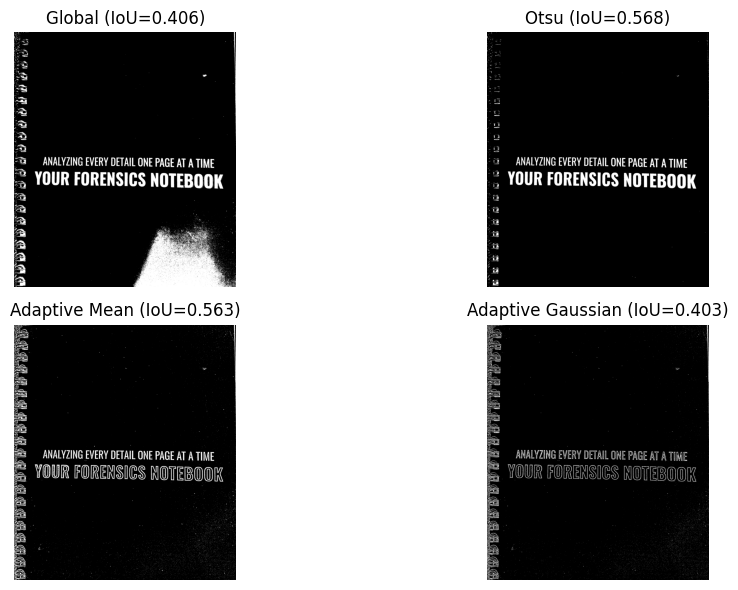

In [10]:
##############################################
# IoU Report
##############################################
methods = {
    "Global": global_threshold(image=img_read(notebook_path)),
    "Otsu": otsu_threshold(image=img_read(notebook_path)),
    "Adaptive Mean": adaptive_mean(image=img_read(notebook_path)),
    "Adaptive Gaussian": adaptive_gaussian(image=img_read(notebook_path))
}

# --- Compute IoU scores ---
scores = {name: iou(mask, ref_mask=img_read(mask_path)) for name, mask in methods.items()}

# --- Print results ---
for name, score in scores.items():
    print(f"{name} IoU: {score:.3f}")

# --- Visualize masks side by side ---
plt.figure(figsize=(12,6))
for i, (name, mask) in enumerate(methods.items(), 1):
    plt.subplot(2,2,i)
    plt.imshow(mask, cmap="gray")
    plt.title(f"{name} (IoU={scores[name]:.3f})")
    plt.axis("off")
plt.tight_layout()
plt.show()


**why adaptive wins (or doesn’t) on this image**</br>
While it didn't win, Adaptive Mean ($0.563$) performed nearly identical to Otsu ($0.568$) because it successfully defended against the dark shadow/artifact at the bottom-right of the document—an area that completely broke standard Global thresholding ($0.406$). It did not win because the lighting gradient across the page was not severe enough. Hence Otsu's method outperformed it.

**Task 2. Watershed for touching objects**

Watershed object count: 33
Unique watershed labels: [-1  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34]


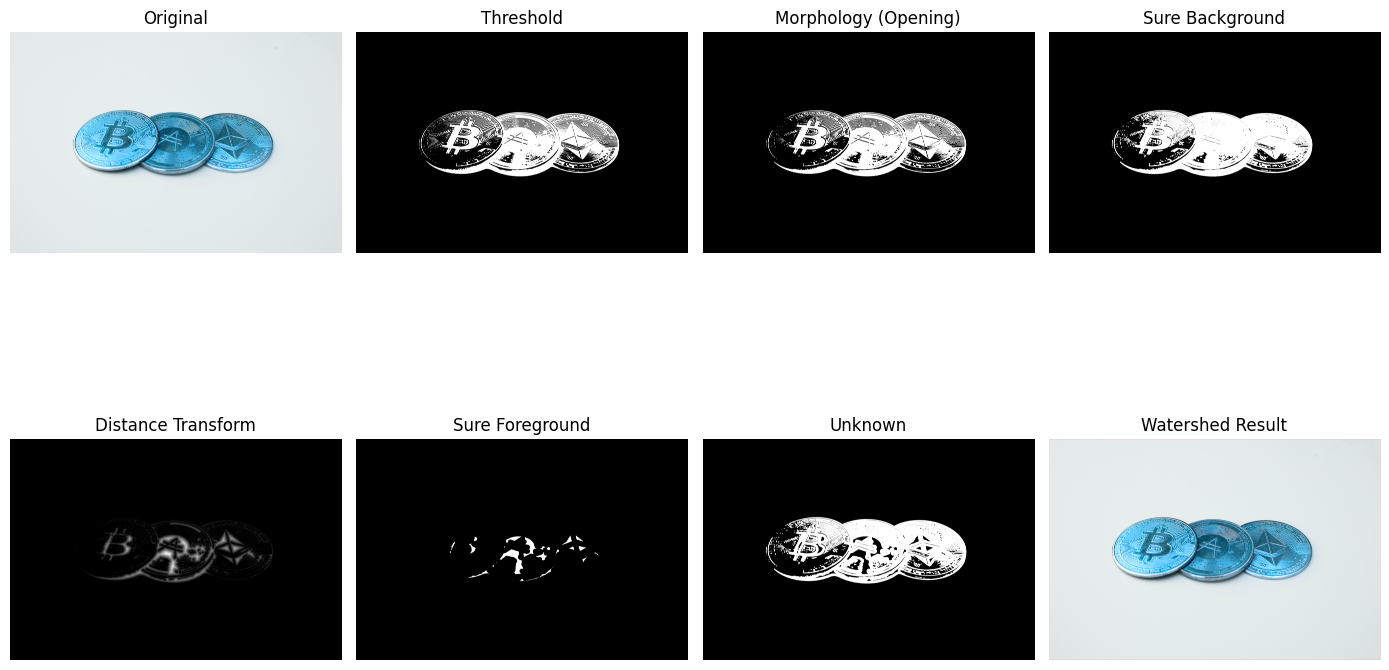

In [14]:

# Load grayscale image
gray_img = img_read(coins_path)
#gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Step 1. Threshold (binary image)
_, thresh = cv2.threshold(gray_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Step 2. Morphological cleanup
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# Step 3. Sure background (dilate)
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Step 4: Distance transform
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
# Normalize for visualization
dist_norm = cv2.normalize(dist_transform, None, 0, 1.0, cv2.NORM_MINMAX)

# Step 5: Sure foreground (threshold distance map)
_, sure_fg = cv2.threshold(dist_transform, 0.4*dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# Step 6: Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Step 7: Marker labelling
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1  # ensure background is not 0 but 1
markers[unknown == 255] = 0

# Step 8: Watershed
rgb_img = img_read(coins_path, gray=False)
markers = cv2.watershed(rgb_img, markers)
segmented = rgb_img.copy()
segmented[markers == -1] = [255,0,0]

# Count unique labels (excluding background and boundary)
labels = np.unique(markers)
object_count = len(labels[(labels != -1) & (labels != 1)])
print("Watershed object count:", object_count)
print("Unique watershed labels:", np.unique(markers))
# Visualization
titles = ["Original", "Threshold", "Morphology (Opening)",
          "Sure Background", "Distance Transform",
          "Sure Foreground", "Unknown", "Watershed Result"]
images = [rgb_img, thresh, opening, sure_bg, dist_norm, sure_fg, unknown, segmented]

plt.figure(figsize=(14,10))
for i in range(len(images)):
    plt.subplot(2,4,i+1)
    cmap = "gray" if len(images[i].shape)==2 else None
    plt.imshow(images[i], cmap=cmap)
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()


**Task 3. GrabCut**

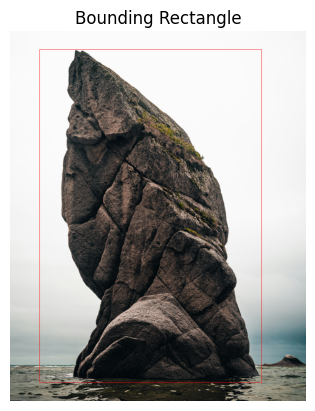

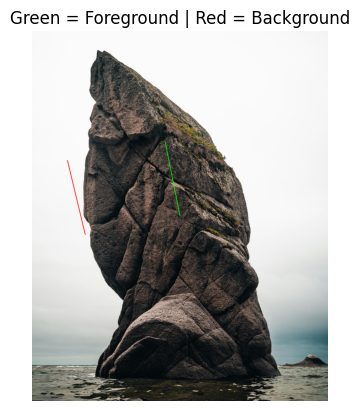

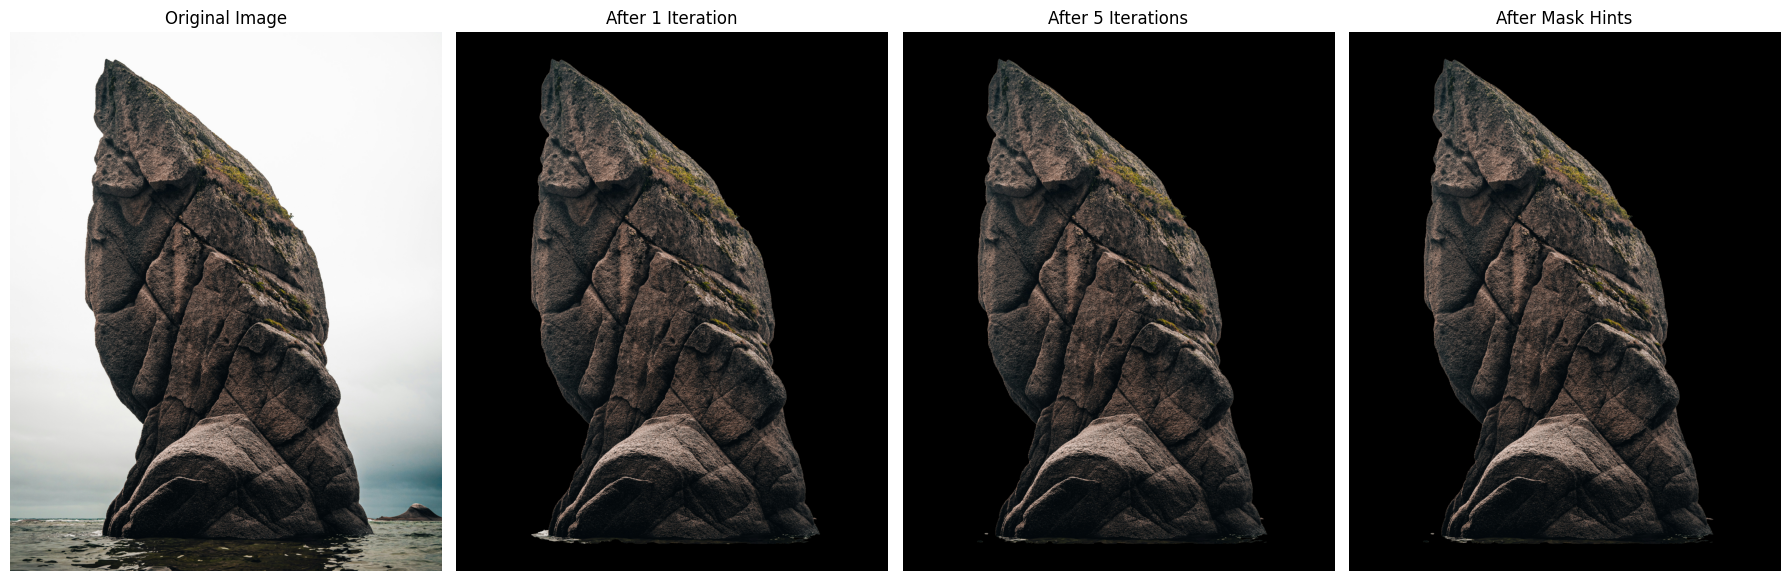

In [ ]:

#####################################
# 1. LOAD IMAGE
#####################################
def load_image(image_path):
    # Read the image from the specified path
    image = cv2.imread(image_path)

    # Check if the image was loaded successfully
    if image is None:
        raise FileNotFoundError(f"Image not found: {image_path}")

    return image


#####################################
# 2. CREATE BOUNDING RECTANGLE
#####################################
def create_rectangle(image):
    # Get the image dimensions
    height, width = image.shape[:2]

    # Define the bounding rectangle around the subject
    rect = (
        int(width * 0.10),   # x-coordinate
        int(height * 0.05),  # y-coordinate
        int(width * 0.75),   # Rectangle width
        int(height * 0.90)   # Rectangle height
    )

    return rect


#####################################
# 3. DISPLAY BOUNDING RECTANGLE
#####################################
def show_rectangle(image, rect):
    # Convert the image from BGR to RGB
    preview = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Extract rectangle coordinates
    x, y, w, h = rect

    # Draw the bounding rectangle around the subject
    cv2.rectangle(
        preview,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        3
    )

    plt.imshow(preview)
    plt.title("Bounding Rectangle")
    plt.axis("off")
    plt.show()


#####################################
# 4. APPLY GRABCUT SEGMENTATION
#####################################
def apply_grabcut(image, rect, iterations=5):
    # Initialize an empty mask
    mask = np.zeros(image.shape[:2], np.uint8)

    # Initialize background and foreground models
    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    # Apply GrabCut using the bounding rectangle
    cv2.grabCut(
        image,
        mask,
        rect,
        bg_model,
        fg_model,
        iterations,
        cv2.GC_INIT_WITH_RECT
    )

    # Convert GrabCut labels into a binary mask
    # Keep definite and probable foreground pixels
    binary_mask = np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        1,
        0
    ).astype(np.uint8)

    # Remove the background from the original image
    result = image * binary_mask[:, :, np.newaxis]

    return result, mask


#####################################
# 5. ADD FOREGROUND AND BACKGROUND MASK HINTS
#####################################
def add_mask_hints(image, mask):
    # Get the image dimensions
    height, width = image.shape[:2]

    # Create a copy of the existing GrabCut mask
    hint_mask = mask.copy()

    # Define foreground stroke coordinates
    # Green stroke identifies definite foreground
    fg_start = (int(width * 0.45), int(height * 0.30))
    fg_end = (int(width * 0.50), int(height * 0.50))

    # Define background stroke coordinates
    # Red stroke identifies definite background
    bg_start = (int(width * 0.12), int(height * 0.35))
    bg_end = (int(width * 0.18), int(height * 0.55))

    # Mark definite foreground pixels
    cv2.line(
        hint_mask,
        fg_start,
        fg_end,
        cv2.GC_FGD,
        thickness=8
    )

    # Mark definite background pixels
    cv2.line(
        hint_mask,
        bg_start,
        bg_end,
        cv2.GC_BGD,
        thickness=8
    )

    # Create a preview showing the mask hints
    preview = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Draw foreground stroke in green
    cv2.line(preview, fg_start, fg_end, (0, 255, 0), 8)

    # Draw background stroke in red
    cv2.line(preview, bg_start, bg_end, (255, 0, 0), 8)

    plt.imshow(preview)
    plt.title("Green = Foreground | Red = Background")
    plt.axis("off")
    plt.show()

    return hint_mask


#####################################
# 6. REFINE SEGMENTATION USING MASK HINTS
#####################################
def refine_grabcut(image, hint_mask, iterations=5):
    # Initialize background and foreground models
    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    # Apply GrabCut using the updated mask
    cv2.grabCut(
        image,
        hint_mask,
        None,
        bg_model,
        fg_model,
        iterations,
        cv2.GC_INIT_WITH_MASK
    )

    # Convert the refined GrabCut mask to binary
    binary_mask = np.where(
        (hint_mask == cv2.GC_FGD) |
        (hint_mask == cv2.GC_PR_FGD),
        1,
        0
    ).astype(np.uint8)

    # Apply the refined mask to the original image
    result = image * binary_mask[:, :, np.newaxis]

    return result, binary_mask


#####################################
# 7. DISPLAY SEGMENTATION RESULTS
#####################################
def display_results(image, result_1, result_5, final_result):
    # Store images and their corresponding titles
    images = [
        image,
        result_1,
        result_5,
        final_result
    ]

    titles = [
        "Original Image",
        "After 1 Iteration",
        "After 5 Iterations",
        "After Mask Hints"
    ]

    # Create four plots for comparison
    fig, axes = plt.subplots(1, 4, figsize=(18, 6))

    for ax, img, title in zip(axes, images, titles):
        # Convert each image from BGR to RGB
        rgb_image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(rgb_image)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


#####################################
# 8. SAVE SEGMENTATION RESULTS
#####################################
def save_results(image, result_1, result_5,
                 final_result, binary_mask):

    # Save results after 1 and 5 iterations
    cv2.imwrite("task3_output/grabcut_1_iteration.png", result_1)
    cv2.imwrite("task3_output/grabcut_5_iterations.png", result_5)

    # Save the refined segmentation
    cv2.imwrite("task3_output/grabcut_refined.png", final_result)

    # Convert original image to BGRA format
    rgba = cv2.cvtColor(image, cv2.COLOR_BGR2BGRA)

    # Set the alpha channel using the binary mask
    rgba[:, :, 3] = binary_mask * 255

    # Save the subject with a transparent background
    cv2.imwrite("task3_output/grabcut_transparent.png", rgba)


#####################################
# 9. MAIN PIPELINE
#####################################
def main():
    # Specify the image path
    image_path = rock_path # rock_path is declared at the start of the notebook

    # Step 1: Load the image
    image = load_image(image_path)

    # Step 2: Create a bounding rectangle
    rect = create_rectangle(image)

    # Step 3: Display the rectangle
    show_rectangle(image, rect)

    # Step 4: Apply GrabCut with 1 iteration
    result_1, mask_1 = apply_grabcut(
        image, rect, iterations=1
    )

    # Step 5: Apply GrabCut with 5 iterations
    result_5, mask_5 = apply_grabcut(
        image, rect, iterations=5
    )

    # Step 6: Add definite foreground/background hints
    hint_mask = add_mask_hints(image, mask_5)

    # Step 7: Refine segmentation using the updated mask
    final_result, binary_mask = refine_grabcut(
        image, hint_mask, iterations=5
    )

    # Step 8: Display all segmentation results
    display_results(
        image, result_1, result_5, final_result
    )

    # Step 9: Save the results
    save_results(
        image,
        result_1,
        result_5,
        final_result,
        binary_mask
    )


#####################################
# 10. RUN PIPELINE
#####################################
if __name__ == "__main__":
    main()


**DeepLabV3’s encoder-decoder structure to the U-Net Idea**

The GrabCut algorithm iteratively models the foreground and background colour distributions using Gaussian Mixture Models (GMMs) to estimate which pixels belong to the subject and which belong to the background. It then uses graph cuts (min-cut/max-flow) to refine the segmentation by minimizing an energy function based on pixel colour similarities and neighbouring pixel relationships, while respecting definite foreground and background mask hints.


**Task 4. Deep segmentation, semantic vs instance**

Selected device: cuda
Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 131MB/s]


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 187MB/s]



Processing: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/street_scene.jpg
Image dimensions: (481, 640)


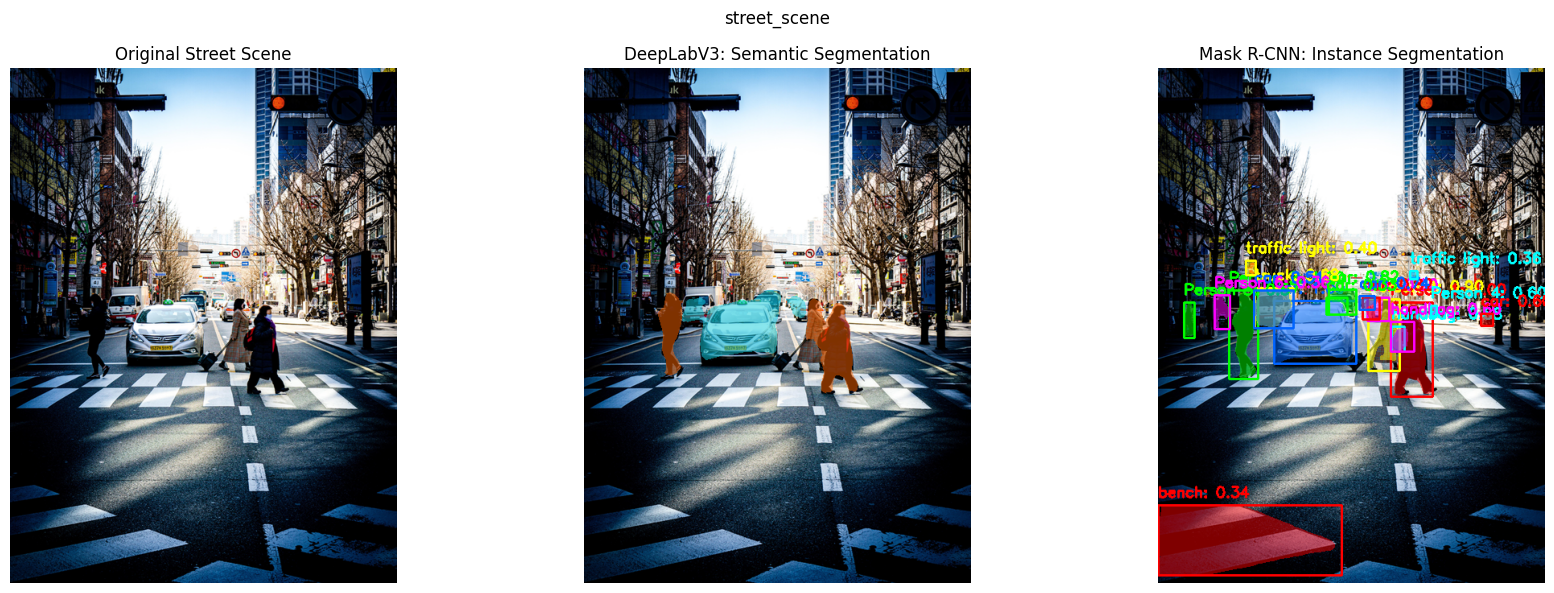


CPU INFERENCE TIME: street_scene
DeepLabV3: 5.033 seconds
Mask R-CNN: 2.077 seconds

Processing: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/people_walking.jpg
Image dimensions: (640, 359)


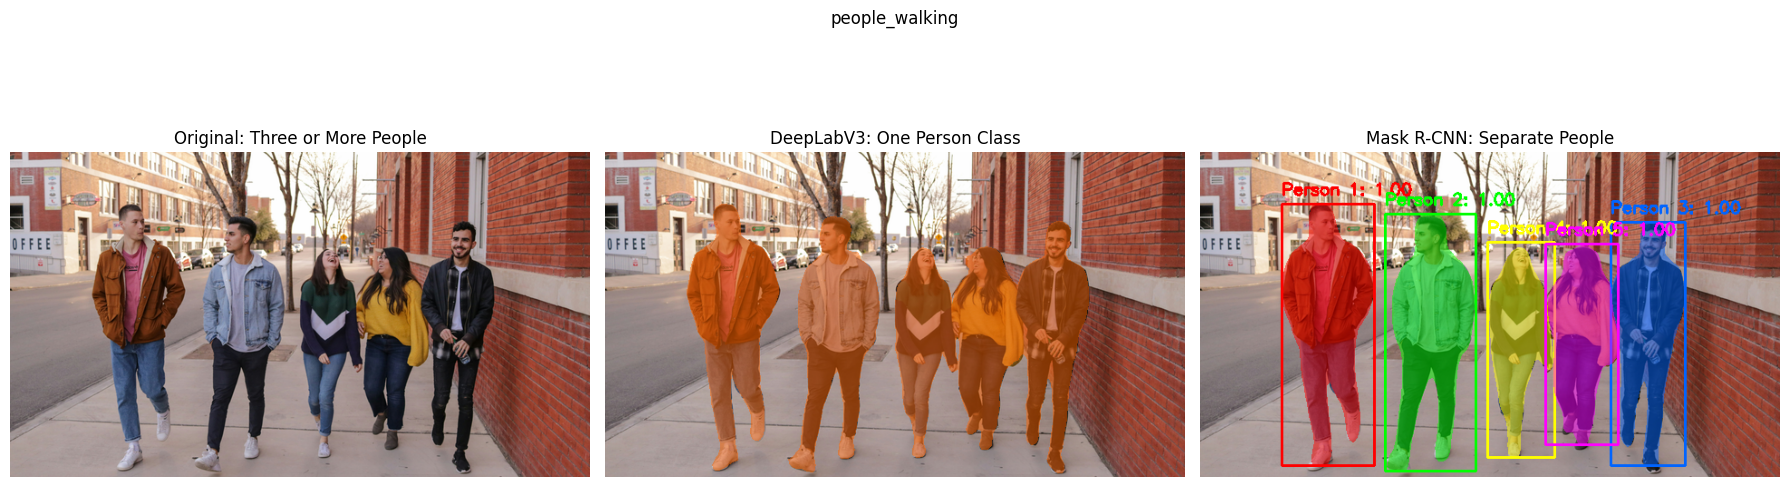


SEMANTIC VS INSTANCE SEGMENTATION
DeepLabV3: All detected people share the same semantic class ('person').
Mask R-CNN: 5 separate person instances detected.

CPU INFERENCE TIME: people_walking
DeepLabV3: 8.378 seconds
Mask R-CNN: 1.839 seconds

PER-IMAGE CPU INFERENCE TIME COMPARISON
         Image  DeepLabV3 CPU (seconds)  Mask R-CNN CPU (seconds)  People Detected
  street_scene                    5.033                     2.077                6
people_walking                    8.378                     1.839                5

Results saved to: task4_output/segmentation_results


In [ ]:

import time
import gc
from pathlib import Path

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image

from torchvision.models.segmentation import (
    deeplabv3_resnet50,
    DeepLabV3_ResNet50_Weights
)

from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)


#####################################
# 1. CONFIGURATION
#####################################

IMAGE_PATHS = [
    street_scene_path,
    people_walking_path
]

OUTPUT_DIR = Path("task4_output/segmentation_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Detection and segmentation thresholds
SCORE_THRESHOLD = 0.3
MASK_THRESHOLD = 0.5

# Maximum image dimension to reduce GPU memory
MAX_IMAGE_SIZE = 640


#####################################
# 2. SELECT COMPUTATION DEVICE
#####################################

def get_device():
    # Prioritize NVIDIA GPU, then Apple GPU, then CPU
    if torch.cuda.is_available():
        device = torch.device("cuda")

    elif (
        hasattr(torch.backends, "mps")
        and torch.backends.mps.is_available()
    ):
        device = torch.device("mps")

    else:
        device = torch.device("cpu")

    print(f"Selected device: {device}")
    return device


#####################################
# 3. CLEAR GPU MEMORY
#####################################

def clear_memory():
    # Collect objects that are no longer needed
    gc.collect()

    # Release unused CUDA memory
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


#####################################
# 4. LOAD PRETRAINED MODELS
#####################################

def load_models():
    # Load pretrained DeepLabV3-ResNet50 weights
    semantic_weights = DeepLabV3_ResNet50_Weights.DEFAULT

    semantic_model = deeplabv3_resnet50(
        weights=semantic_weights
    ).eval()

    # Load pretrained Mask R-CNN-ResNet50 weights
    instance_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

    instance_model = maskrcnn_resnet50_fpn(
        weights=instance_weights,

        # Reduce image size inside Mask R-CNN
        min_size=480,
        max_size=640,

        # Limit number of final object detections
        box_detections_per_img=20
    ).eval()

    # Keep both models on CPU initially
    # Only the active model moves to GPU

    return (
        semantic_model,
        instance_model,
        semantic_weights,
        instance_weights
    )


#####################################
# 5. LOAD AND RESIZE IMAGE
#####################################

def load_image(image_path):
    # Read image and convert it to RGB
    image = Image.open(image_path).convert("RGB")

    # Resize large images to reduce GPU memory usage
    # Aspect ratio is preserved
    image.thumbnail(
        (MAX_IMAGE_SIZE, MAX_IMAGE_SIZE),
        Image.Resampling.LANCZOS
    )

    print(f"Image dimensions: {image.size}")

    return image


#####################################
# 6. PREPROCESS IMAGE
#####################################

def preprocess_image(
    image,
    semantic_weights,
    instance_weights
):
    # DeepLabV3 preprocessing includes normalization
    # and resizing using pretrained weight transforms
    semantic_tensor = semantic_weights.transforms()(
        image
    ).unsqueeze(0)

    # Mask R-CNN preprocessing converts image to tensor
    # Model handles any additional internal resizing
    instance_tensor = instance_weights.transforms()(
        image
    )

    # Keep both tensors on CPU initially
    return semantic_tensor, instance_tensor


#####################################
# 7. RUN GPU/CPU INFERENCE
#####################################

def run_inference(
    model,
    inputs,
    model_type,
    device
):
    # Move only the active model to selected device
    model = model.to(device).eval()

    # Move input tensor to selected device
    inputs_device = inputs.to(device)

    # Disable gradient calculations
    with torch.inference_mode():

        if model_type == "semantic":
            # Run DeepLabV3 semantic segmentation
            output = model(inputs_device)["out"]

            # Move prediction to CPU
            output = output.cpu()

        elif model_type == "instance":
            # Run Mask R-CNN instance segmentation
            prediction = model([inputs_device])[0]

            # Move all prediction tensors to CPU
            output = {
                key: value.cpu()
                for key, value in prediction.items()
            }

        else:
            raise ValueError("Unknown model type")

    # Release GPU input tensor
    del inputs_device

    # Move model back to CPU
    model.to("cpu")

    # Clear unused GPU memory
    clear_memory()

    return output


#########################################
# 8. CREATE SEMANTIC SEGMENTATION OVERLAY
#########################################

def semantic_overlay(
    image,
    output,
    weights,
    people_only=False
):
    # Get original image dimensions
    width, height = image.size

    # Resize prediction to original image dimensions
    output = torch.nn.functional.interpolate(
        output,
        size=(height, width),
        mode="bilinear",
        align_corners=False
    )

    # Predict class with highest score for each pixel
    segmentation = output.argmax(1)[0].cpu().numpy()

    # Extract category names
    categories = weights.meta["categories"]

    # Generate consistent colours for classes
    rng = np.random.default_rng(42)

    colours = rng.integers(
        0,
        256,
        size=(len(categories), 3),
        dtype=np.uint8
    )

    # Set background colour to black
    colours[0] = [0, 0, 0]

    # Assign one colour to the person class
    person_id = categories.index("person")
    colours[person_id] = [255, 100, 0]

    # Convert image to NumPy array
    original = np.array(image)
    overlay = original.copy()

    if people_only:
        # All people share ONE semantic class
        foreground = segmentation == person_id
    else:
        # Display all recognized semantic classes
        foreground = segmentation != 0

    # Assign colours according to predicted classes
    colour_mask = colours[segmentation]

    # Blend original image and semantic colours
    overlay[foreground] = (
        0.5 * original[foreground]
        + 0.5 * colour_mask[foreground]
    ).astype(np.uint8)

    return overlay, segmentation


#########################################
# 9. CREATE INSTANCE SEGMENTATION OVERLAY
#########################################

def instance_overlay(
    image,
    output,
    weights,
    people_only=False
):
    # Convert image to NumPy array
    overlay = np.array(image).copy()

    # Extract predictions
    masks = output["masks"].cpu().numpy()
    labels = output["labels"].cpu().numpy()
    scores = output["scores"].cpu().numpy()
    boxes = output["boxes"].cpu().numpy()

    categories = weights.meta["categories"]

    # Different colours for individual instances
    instance_colours = [
        (255, 0, 0),     # Red
        (0, 255, 0),     # Green
        (0, 100, 255),   # Blue
        (255, 255, 0),   # Yellow
        (255, 0, 255),   # Magenta
        (0, 255, 255)    # Cyan
    ]

    # Count people and instances
    person_count = 0
    instance_count = 0

    # Store detected objects
    detected_objects = []

    # Process each detected instance
    for index, score in enumerate(scores):

        # Ignore low-confidence detections
        if score < SCORE_THRESHOLD:
            continue

        # Get object class
        class_name = categories[labels[index]]

        # For the people image, display people only
        if people_only and class_name != "person":
            continue

        # Convert predicted mask into binary mask
        mask = masks[index, 0] > MASK_THRESHOLD

        if not mask.any():
            continue

        # Count the detected instance
        instance_count += 1

        # Assign a different colour to each instance
        colour = instance_colours[
            (instance_count - 1) % len(instance_colours)
        ]

        # Apply colour-coded instance mask
        overlay[mask] = (
            0.5 * overlay[mask]
            + 0.5 * np.array(colour)
        ).astype(np.uint8)

        # Identify individual people
        if class_name == "person":
            person_count += 1
            object_name = f"Person {person_count}"
        else:
            object_name = class_name

        # Extract bounding box coordinates
        x1, y1, x2, y2 = boxes[index].astype(int)

        # Keep bounding box inside image boundaries
        height, width = overlay.shape[:2]

        x1 = max(0, min(x1, width - 1))
        y1 = max(0, min(y1, height - 1))
        x2 = max(0, min(x2, width - 1))
        y2 = max(0, min(y2, height - 1))

        # Draw bounding box
        cv2.rectangle(
            overlay,
            (x1, y1),
            (x2, y2),
            colour,
            2
        )

        # Add object label and confidence
        label = f"{object_name}: {score:.2f}"

        cv2.putText(
            overlay,
            label,
            (x1, max(20, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            colour,
            2
        )

        # Store detected object information
        detected_objects.append({
            "name": object_name,
            "score": float(score),
            "mask": mask
        })

    return overlay, detected_objects, person_count


#####################################
# 10. MEASURE CPU INFERENCE TIME
#####################################

def measure_cpu_time(
    model,
    inputs,
    model_type
):
    # Ensure model is running on CPU
    model = model.to("cpu").eval()

    # Move input tensor to CPU
    inputs = inputs.to("cpu")

    with torch.inference_mode():

        # Warm-up CPU inference (not timed)
        if model_type == "semantic":
            model(inputs)
        else:
            model([inputs])

        # Start CPU timing
        start_time = time.perf_counter()

        # Run one timed CPU inference
        if model_type == "semantic":
            model(inputs)
        else:
            model([inputs])

        # Calculate elapsed time
        elapsed_time = time.perf_counter() - start_time

    return elapsed_time


#####################################
# 11. DISPLAY SEGMENTATION RESULTS
#####################################

def display_results(
    image,
    semantic_result,
    instance_result,
    image_name,
    people_only=False
):
    # Create three subplots for comparison
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6)
    )

    images = [
        np.array(image),
        semantic_result,
        instance_result
    ]

    if people_only:
        titles = [
            "Original: Three or More People",
            "DeepLabV3: One Person Class",
            "Mask R-CNN: Separate People"
        ]

    else:
        titles = [
            "Original Street Scene",
            "DeepLabV3: Semantic Segmentation",
            "Mask R-CNN: Instance Segmentation"
        ]

    # Display the original and both predictions
    for ax, img, title in zip(
        axes,
        images,
        titles
    ):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(image_name)
    plt.tight_layout()

    # Save comparison figure
    plt.savefig(
        OUTPUT_DIR / f"{image_name}_comparison.png",
        bbox_inches="tight",
        dpi=150
    )

    plt.show()
    plt.close(fig)


#####################################
# 12. SAVE INDIVIDUAL OVERLAYS
#####################################

def save_overlays(
    semantic_result,
    instance_result,
    image_name
):
    # Save semantic segmentation result
    Image.fromarray(semantic_result).save(
        OUTPUT_DIR / f"{image_name}_semantic.png"
    )

    # Save instance segmentation result
    Image.fromarray(instance_result).save(
        OUTPUT_DIR / f"{image_name}_instance.png"
    )


#####################################
# 13. MAIN PIPELINE
#####################################

def main():
    # Select computation device
    device = get_device()

    # Load pretrained segmentation models
    (
        semantic_model,
        instance_model,
        semantic_weights,
        instance_weights
    ) = load_models()

    # Store per-image CPU inference times
    timing_results = []

    # Process the street scene and people image
    for image_index, image_path in enumerate(IMAGE_PATHS):

        print(f"\nProcessing: {image_path}")

        # Load and resize image
        image = load_image(image_path)
        image_name = Path(image_path).stem

        # Second image demonstrates the conceptual difference
        people_only = image_index == 1

        # Preprocess image for both models
        semantic_input, instance_input = preprocess_image(
            image,
            semantic_weights,
            instance_weights
        )

        # Run DeepLabV3 using preferred device
        semantic_output = run_inference(
            semantic_model,
            semantic_input,
            "semantic",
            device
        )

        # Run Mask R-CNN using preferred device
        instance_output = run_inference(
            instance_model,
            instance_input,
            "instance",
            device
        )

        # Create semantic segmentation overlay
        semantic_result, segmentation = semantic_overlay(
            image,
            semantic_output,
            semantic_weights,
            people_only=people_only
        )

        # Create instance segmentation overlay
        instance_result, objects, person_count = instance_overlay(
            image,
            instance_output,
            instance_weights,
            people_only=people_only
        )

        # Display original and segmented images
        display_results(
            image,
            semantic_result,
            instance_result,
            image_name,
            people_only=people_only
        )

        # Save colour-coded overlays
        save_overlays(
            semantic_result,
            instance_result,
            image_name
        )

        # Demonstrate semantic vs instance segmentation
        if people_only:
            print("\nSEMANTIC VS INSTANCE SEGMENTATION")

            print(
                "DeepLabV3: All detected people share "
                "the same semantic class ('person')."
            )

            print(
                f"Mask R-CNN: {person_count} separate "
                "person instances detected."
            )

            # Check whether at least three people were detected
            if person_count < 3:
                print(
                    "Warning: Fewer than 3 people detected. "
                    "Check image clarity or confidence threshold."
                )

        # Measure DeepLabV3 CPU inference time
        semantic_cpu_time = measure_cpu_time(
            semantic_model,
            semantic_input,
            "semantic"
        )

        # Measure Mask R-CNN CPU inference time
        instance_cpu_time = measure_cpu_time(
            instance_model,
            instance_input,
            "instance"
        )

        # Record CPU inference measurements
        timing_results.append({
            "Image": image_name,
            "DeepLabV3 CPU (seconds)": round(
                semantic_cpu_time, 3
            ),
            "Mask R-CNN CPU (seconds)": round(
                instance_cpu_time, 3
            ),
            "People Detected": person_count
        })

        # Report per-image CPU inference times
        print(f"\nCPU INFERENCE TIME: {image_name}")
        print(
            f"DeepLabV3: {semantic_cpu_time:.3f} seconds"
        )
        print(
            f"Mask R-CNN: {instance_cpu_time:.3f} seconds"
        )

        # Remove image-specific tensors and predictions
        del semantic_input
        del instance_input
        del semantic_output
        del instance_output

        # Release unused memory
        clear_memory()

    # Create CPU inference timing table
    timing_df = pd.DataFrame(timing_results)

    print("\nPER-IMAGE CPU INFERENCE TIME COMPARISON")
    print(timing_df.to_string(index=False))

    # Save timing results as CSV
    timing_df.to_csv(
        OUTPUT_DIR / "cpu_inference_times.csv",
        index=False
    )

    print(f"\nResults saved to: {OUTPUT_DIR}")


#####################################
# 14. RUN PIPELINE
#####################################

if __name__ == "__main__":
    main()


**DeepLabV3’s encoder-decoder structure to the U-Net**

DeepLabV3 and U-Net both use the encoder-decoder concept for image segmentation. The encoder extracts important features from an image and the decoder or upsampling stage produces a pixel-level segmentation map.
U-Net uses skip connections to combine low-level spatial details with high-level features,resulting in preservation of object boundaries. In contrast, DeepLabV3 uses Atrous Spatial Pyramid Pooling (ASPP) to capture features at multiple scales and then upsamples its predictions, without U-Net's symmetrical decoder structure.

**Task 5. Deploy a segmentation studio**

[huggingface deployment Url](https://huggingface.co/spaces/kbesa/image-segmentation-lab)

**Note:** I was unable to run it in huggingface as gradio apps needed a paid up plan. But I tested it with googlecolab